In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import pandas as pd

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

In [2]:
from langchain_core.messages import HumanMessage


In [3]:
from src.lib.knowledge import Knowledge
from src.agents.support_agent import SupportAgent, SupportState, get_support_agent
from src.models.workflow import WorkflowSettings

In [4]:
df = pd.read_csv("../data/transactions.csv", index_col="transaction_id", parse_dates=["transaction_date"])
df.head()

,transaction_date,transaction_type,category,amount_ngn,payment_channel,description,suspicious_flag
transaction_id,,,,,,,
TXN0001,2026-04-13,Expense,Utilities,24563.25,POS,Utilities transaction,0
TXN0002,2026-09-28,Expense,Bank Charges,11339.64,Direct Debit,Bank Charges transaction,0
TXN0003,2026-04-17,Income,Sales,16232.84,Bank Transfer,Sales transaction,0
TXN0004,2026-03-13,Expense,Utilities,3152.87,Direct Debit,Utilities transaction,0
TXN0005,2026-07-08,Income,Sales,18004.45,Cash,Sales transaction,1


In [5]:
km = Knowledge("testing")
# await km.ingest_from_dataframe(df, "testing")

In [6]:
agent = get_support_agent(["testing"], settings=WorkflowSettings(online=False))

In [7]:
agent.invoke(SupportState(messages=[HumanMessage(content="What is the most popular category?")]))

[2026-10-22 14:34:26] [INFO] [SupportAgent] - [Guardrailing message]
[2026-10-22 14:34:30] [INFO] [SearchWorkflow] - [Invoked]
[2026-10-22 14:34:30] [INFO] [Knowledge] - [Looking for documents]
[2026-10-22 14:34:34] [INFO] [SearchWorkflow] - [Retrieved Documents]
[2026-10-22 14:34:37] [INFO] [SearchWorkflow] - [Invoked]
[2026-10-22 14:34:37] [INFO] [Knowledge] - [Looking for documents]
[2026-10-22 14:34:37] [INFO] [SearchWorkflow] - [Retrieved Documents]


"I couldn't find any transaction data to determine which category is the most popular. Please ensure your accounts are linked or upload your transaction statement so I can analyze this for you.\n\n**Next Step:** Upload your latest transaction CSV or connect your bank account to get this analysis."

In [8]:
# events = agent.stream(SupportState(messages=[HumanMessage(content="Hello, I need help with my account.")]))
# for event in events:
#     print(event)

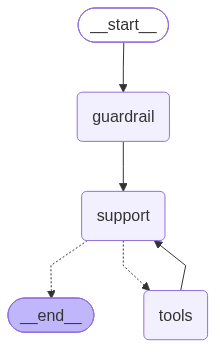

In [9]:
agent.graph